#  机器学习练习 Scikit-learn的介绍

Scikit-learn是基于NumPy、SciPy和Matplotlib的开源Python机器学习包，它封装了一系列数据预处理、机器学习算法、模型选择等工具，是数据分析师首选的机器学习工具包。

自2007年发布以来，Scikit-learn已经成为Python重要的机器学习库了，Scikit-learn简称sklearn，支持包括分类、回归、降维和聚类四大机器学习算法，还包括了特征提取、数据处理和模型评估三大模块。

在工程应用中，用python手写代码来从头实现一个算法的可能性非常低，这样不仅耗时耗力，还不一定能够写出构架清晰，稳定性强的模型。更多情况下，是分析采集到的数据，根据数据特征选择适合的算法，在工具包中调用算法，调整算法的参数，获取需要的信息，从而实现算法效率和效果之间的平衡。而sklearn，正是这样一个可以帮助我们高效实现算法应用的工具包。

sklearn有一个完整而丰富的官网，里面讲解了基于sklearn对所有算法的实现和简单应用。然而，这个官网是全英文的，并且现在没有特别理想的中文接口，市面上也没有针对sklearn非常好的书。因此，这次课目的就是向大家介绍sklearn的应用。

英文官方文档：https://scikit-learn.org/stable/

中文官方文档：https://scikit-learn.org.cn/

## 1.  Scikit-learn概述

Scikit-Learn (简称 Sklearn) 是基于 Python 语言的机器学习工具。它建立在 NumPy、
SciPy、Pandas和 Matplotlib 之上，对常用的机器学习方法进行了封装，例如，分类、回归、聚类、降维、模型评估、数据预处理等，我们只需调用对应的接口即可。

Scikit-Learn库的算法主要有四类：分类、回归、聚类、降维。其中：

1.  常用的回归：线性回归、决策树回归、SVM回归、KNN
    回归；集成回归：随机森林、Adaboost、GradientBoosting、Bagging、ExtraTrees。

2.  常用的分类：线性分类、决策树、SVM、KNN，朴素贝叶斯；集成分类：随机森林、Adaboost、GradientBoosting、Bagging、ExtraTrees。

3.  常用聚类：K均值(K-means)、层次聚类(Hierarchical clustering)、DBSCAN。

4.  常用降维：LinearDiscriminantAnalysis、PCA。

![](images/sklearn.jpeg)

上图代表了Scikit-Learn算法选择的一个简单路径，这个路径图代表：蓝色圆圈是判断条件，绿色方框是可以选择的算法，我们可以根据自己的数据特征和任务目标去找一条自己的操作路线。

Scikit-Learn中包含众多数据预处理和特征工程相关的模块，但其实Sklearn六大板块中有两块都是关于数据预处理和特征工程的，两个板块互相交互，为建模之前的全部工程打下基础。

## 2.Scikit-learn主要用法

### 2.1.基本建模符号

基本建模的符号标记见表3-1：


| 符号    | 代表含义 | 符号    | 代表含义   |
|---------|----------|---------|------------|
| X_train | 训练数据 | y_train | 训练集标签 |
| X_test  | 测试数据 | y_test  | 测试集标签 |
| X       | 完整数据 | y       | 数据标签   |
|         |          | y_pred  | 预测标签   |

### 2.1.1.导入工具包

导入工具包的方法如下(这里使用伪代码)：

`from sklearn import 包名称`

`from sklearn.库名称 import 包名称`

代码示例：

In [1]:
from sklearn import datasets, preprocessing  
#导入数据集，数据预处理库  
from sklearn.model_selection import train_test_split    
#从模型选择库导入数据切分包  
from sklearn.linear_model import LinearRegression    
#从线性模型库导入线性回归包  
from sklearn.metrics import r2_score  
#从评价指标库导入R2评价指标  

import numpy as np
np.set_printoptions(precision=5,suppress=True)

### 2.1.2 导入数据

导入数据的方法如下：

`from sklearn.datasets import 数据名称`

Scikit-learn支持以NumPy的arrays对象、Pandas对象、SciPy的稀疏矩阵及其他可转换为数值型arrays的数据结构作为其输入，前提是数据必须是数值型的。

sklearn.datasets模块提供了一系列加载和获取著名数据集如鸢尾花、波士顿房价、Olivetti人脸、MNIST数据集等的工具，也包括了一些toy
data如S型数据等的生成工具。

Scikit-learn内置了很多可以用于机器学习的数据，可以用两行代码就可以使用这些数据。内置数据分为可以直接使用的数据集、需下载的数据集以及生成数据集。

- 1.可以直接使用的自带数据集

此类数据集可以直接导入使用数据，数据集和描述见下表：


| 数据集名称               | 描述           | 类型       | 维度           |
|--------------------------|----------------|------------|----------------|
| load_boston              | Boston房屋价格 | 回归       | 506\*13        |
| fetch_california_housing | 加州住房       | 回归       | 20640\*9       |
| load_diabetes            | 糖尿病         | 回归       | 442\*10        |
| load_digits              | 手写字         | 分类       | 1797\*64       |
| load_breast_cancer       | 乳腺癌         | 分类、聚类 | (357+212)\*30  |
| load_iris                | 鸢尾花         | 分类、聚类 | (50\*3)\*4     |
| load_wine                | 葡萄酒         | 分类       | (59+71+48)\*13 |
| load_linnerud            | 体能训练       | 多分类     | 20             |

- 2.需要下载的自带数据集

此类数据集第一次使用，需要联网下载数据，数据集和描述见下表：


| 数据集名称                    | 描述                                                                                                                                                                                                             |
|-------------------------------|------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| fetch_20newsgroups            | 用于文本分类、文本挖据和信息检索研究的国际标准数据集之一。数据集收集了大约20,000左右的新闻组文档，均匀分为20个不同主题的新闻组集合。返回一个可以被文本特征提取器                                                 |
| fetch_20newsgroups_vectorized | 这是上面这个文本数据的向量化后的数据，返回一个已提取特征的文本序列，即不需要使用特征提取器                                                                                                                       |
| fetch_california_housing      | 加利福尼亚的房价数据，总计20640个样本，每个样本8个属性表示，以及房价作为target，所有属性值均为number，详情可调用。如：fetch_california_housing( )['DESCR']，了解每个属性的具体含义；                             |
| fetch_covtype                 | 森林植被类型，总计581012个样本，每个样本由54个维度表示(12个属性，其中2个分别是onehot4维和onehot40维)，以及target表示植被类型1-7，所有属性值均为number，详情可调用fetch_covtype( )['DESCR']了解每个属性的具体含义 |
| fetch_kddcup99                | KDD竞赛在1999年举行时采用的数据集，KDD99数据集仍然是网络入侵检测领域的事实Benckmark，为基于计算智能的网络入侵检测研究奠定基础，包含41项特征                                                                      |
| fetch_lfw_pairs               | 该任务称为人脸验证：给定一对两张图片，二分类器必须预测这两个图片是否来自同一个人。                                                                                                                               |
| fetch_lfw_people              | 打好标签的人脸数据集                                                                                                                                                                                             |
| fetch_mldata                  | 从 mldata.org 中下载数据集                                                                                                                                                                                       |
| fetch_olivetti_faces          | Olivetti 脸部图片数据集                                                                                                                                                                                          |
| fetch_rcv1                    | 路透社新闻语聊数据集                                                                                                                                                                                             |
| fetch_species_distributions   | 物种分布数据集                                                                                                                                                                                                   |

- 3.生成数据集

此类数据集可以用来分类任务，可以用来回归任务，可以用来聚类任务，用于流形学习的，用于因子分解任务的，用于分类任务和聚类任务的：这些函数产生样本特征向量矩阵以及对应的类别标签集合，数据集和描述见下表：


| 数据集名称              | 描述                                                                                                                       |
|-------------------------|----------------------------------------------------------------------------------------------------------------------------|
| make_blobs              | 多类单标签数据集，为每个类分配一个或多个正态分布的点集                                                                     |
| make_classification     | 多类单标签数据集，为每个类分配一个或多个正态分布的点集，提供了为数据添加噪声的方式，包括维度相关性，无效特征以及冗余特征等 |
| make_gaussian-quantiles | 将一个单高斯分布的点集划分为两个数量均等的点集，作为两类                                                                   |
| make_hastie-10-2        | 产生一个相似的二元分类数据集，有10个维度                                                                                   |
| make_circle和make_moons | 产生二维二元分类数据集来测试某些算法的性能，可以为数据集添加噪声，可以为二元分类器产生一些球形判决界面的数据               |

代码示例：

In [2]:
#导入内置的乳腺癌数据集
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()

In [3]:
#数据是以「字典」格式存储的，看看breast cancer数据集的键值有哪些。
cancer.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename'])

In [4]:
#定义数据、标签
X = cancer.data
y = cancer.target

In [5]:
X.shape

(569, 30)

In [6]:
y.shape

(569,)

In [7]:
cancer['feature_names']

array(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error',
       'fractal dimension error', 'worst radius', 'worst texture',
       'worst perimeter', 'worst area', 'worst smoothness',
       'worst compactness', 'worst concavity', 'worst concave points',
       'worst symmetry', 'worst fractal dimension'], dtype='<U23')

In [8]:
# 查看乳腺癌数据集的类别标签  
print("类别标签:", cancer.target_names) 

类别标签: ['malignant' 'benign']


## 2.2.数据预处理

### 2.2.1.数据划分

机器学习的数据，可以划分为训练集、验证集和测试集，也可以划分为训练集和测试集。

![](images/8dcde98a61699afa97dc30596cbc71d5.png)


代码示例：

In [9]:
from sklearn.model_selection import train_test_split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X,#可以是列表、numpy数组、scipy稀疏矩阵或pandas的DataFrame
                                                    y,#可以是列表、numpy数组、scipy稀疏矩阵或pandas的DataFrame
                                                    random_state=12,#若为整数时，每次生成的数据都相同
                                                    stratify=y,#若不为None时，划分出来的测试集或训练集中，其类标签的比例同输入的数组中类标签的比例相同，可以用于处理不均衡的数据集
                                                    test_size=0.3)#0.0到1.0之间
#将完整数据集的70%作为训练集，30%作为测试集，


参考资料：

https://scikit-learn.org.cn/view/649.html

https://www.geeksforgeeks.org/how-to-implement-stratified-sampling-with-scikit-learn/

https://www.cnblogs.com/Yanjy-OnlyOne/p/11288098.html

-  数据集拆分是为了验证模型在训练集和测试集是否过拟合，使用train_test_split的目的是保证从数据集中均匀拆分出测试集。这里，简单把30%的数据集拿出来用作测试集。

- 可通过设置shuffle=True 提前打乱数据。

-  使用pandas查看数据（可选内容），这部分自学

In [13]:
import pandas as pd

In [14]:
cancer_df=pd.DataFrame(cancer.data)
cancer_df.head()

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [15]:
cancer_df['class']=cancer.target#增加一列
cancer_df

,0,1,2,3,4,5,6,7,8,9,...,21,22,23,24,25,26,27,28,29,class
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0


In [16]:
column_name = cancer['feature_names'].tolist()
column_name.append('class')
column_name

['mean radius',
 'mean texture',
 'mean perimeter',
 'mean area',
 'mean smoothness',
 'mean compactness',
 'mean concavity',
 'mean concave points',
 'mean symmetry',
 'mean fractal dimension',
 'radius error',
 'texture error',
 'perimeter error',
 'area error',
 'smoothness error',
 'compactness error',
 'concavity error',
 'concave points error',
 'symmetry error',
 'fractal dimension error',
 'worst radius',
 'worst texture',
 'worst perimeter',
 'worst area',
 'worst smoothness',
 'worst compactness',
 'worst concavity',
 'worst concave points',
 'worst symmetry',
 'worst fractal dimension',
 'class']

In [17]:
cancer_df.columns=column_name
cancer_df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,class
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [18]:
cancer_df['class'].value_counts()

1    357
0    212
Name: class, dtype: int64

In [19]:
cancer_df.shape

(569, 31)

In [20]:
cols = cancer_df.shape[1]
cols

31

In [21]:
# set X (training data) and y (target variable)

X = cancer_df.iloc[:,:-1]#X是所有行，去掉最后一列
y = cancer_df.iloc[:,-1]#X是所有行，最后一列
#下面的代码作用一样
#X = cancer_df.iloc[:,:cols-1]#X是所有行，去掉最后一列
#y = cancer_df.iloc[:,cols-1:]#X是所有行，最后一列

In [22]:
X.shape

(569, 30)

In [23]:
y.shape

(569,)

- 下面的代码用于演示stratify参数的作用：

In [27]:
X_train, X_test, y_train, y_test= train_test_split(X, y, train_size=0.8, random_state=None, shuffle=True, stratify=None)
print("Class distribution of train set")
print(y_train.value_counts())
print()
print("Class distribution of test set")
print(y_test.value_counts())


Class distribution of train set
1    278
0    177
Name: class, dtype: int64

Class distribution of test set
1    79
0    35
Name: class, dtype: int64


In [28]:
X_train, X_test, y_train, y_test= train_test_split(X,y, train_size=0.8, random_state=None, shuffle=True, stratify=y)
print("Class distribution of train set")
print(y_train.value_counts())
print()
print("Class distribution of test set")
print(y_test.value_counts())


Class distribution of train set
1    285
0    170
Name: class, dtype: int64

Class distribution of test set
1    72
0    42
Name: class, dtype: int64


### 2.2.2.数据变换操作

sklearn.preprocessing模块包含了数据变换的主要操作（表3-5），数据变换的方法如下：

`from sklearn.preprocessing import 库名称`

下表使用Scikit-learn进⾏数据变换

| 预处理操作           | 库名称             |
|----------------------|--------------------|
| 标准化               | StandardScaler     |
| 最小最大标准化       | MinMaxScaler       |
| One-Hot编码          | OneHotEncoder      |
| 归一化               | Normalizer         |
| 二值化(单个特征转换) | Binarizer          |
| 标签编码             | LabelEncoder       |
| 缺失值填补           | Imputer            |
| 多项式特征生成       | PolynomialFeatures |

代码示例：

In [33]:
#使⽤Scikit-learn进⾏数据标准化
from sklearn.preprocessing import StandardScaler,MinMaxScaler

#构建转换器实例
#scaler = MinMaxScaler()#实例化
scaler = StandardScaler()#实例化
# https://scikit-learn.org/0.15/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler
#https://scikit-learn.org.cn/view/753.html

In [31]:
import sklearn
sklearn.__version__

'0.24.1'

In [35]:
scaler.mean_

array([-0.,  0.,  0., -0.,  0., -0.,  0.,  0.,  0., -0., -0.,  0., -0.,
        0.,  0., -0.,  0., -0.,  0., -0., -0.,  0., -0., -0.,  0., -0.,
        0.,  0., -0., -0.])

In [37]:
scaler.n_features_in_

30

In [49]:
from sklearn.preprocessing import StandardScaler
data = np.array([[0, 0], [0, 0], [7, 0], [1, 1]])
scaler = StandardScaler()
print(scaler.fit(data))
print(scaler.mean_)
print(scaler.transform(data))
print(scaler.transform([[2, 2]]))

StandardScaler()
[2.   0.25]
[[-0.68599 -0.57735]
 [-0.68599 -0.57735]
 [ 1.71499 -0.57735]
 [-0.343    1.73205]]
[[0.      4.04145]]


In [50]:
data.shape

(4, 2)

In [48]:
X_train.shape

(398, 30)

In [34]:
X_train = scaler.fit_transform(X_train)

In [21]:
#拟合及转换
X_train = scaler.fit_transform(X_train)
print("X_train.shape is : ", X_train.shape)
X_test = scaler.fit_transform(X_test)
print("X_test.shape is : ", X_test.shape)

X_train.shape is :  (398, 30)
X_test.shape is :  (171, 30)


### 2.2.3.特征选择

特征选择的方法如下：

#导入特征选择库

`from sklearn import feature_selection as fs`

-   过滤式(Filter)

#保留得分排名前k的特征(top k方式)

`fs.SelectKBest(score_func, k)`

#交叉验证特征选择

`fs.RFECV(estimator, scoring=“r2”)`

-   封装式(Wrapper)，结合交叉验证的递归特征消除法，自动选择最优特征个数：

`fs.SelectFromModel(estimator)`

-   嵌入式(Embedded)，从模型中自动选择特征，任何具有coef_或者feature_importances_的基模型都可以作为estimator参数传入。

In [31]:
from sklearn.feature_selection import SelectKBest,chi2# 分类
#from sklearn.feature_selection import SelectKBest,f_regression#回归

-   对于回归问题: score_func可以选择f_regression 或者 mutual_info_regression


-   对于分类问题: score_func可以选择chi2, f_classif 或者 mutual_info_classif

In [32]:
# 初始化 SelectKBest 并指定评分函数和要选择的特征数
selector = SelectKBest(chi2, k=2)
# 拟合和转换数据 
X_train_new = selector.fit_transform(X_train, y_train)

In [33]:
cancer['feature_names'] 

array(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error',
       'fractal dimension error', 'worst radius', 'worst texture',
       'worst perimeter', 'worst area', 'worst smoothness',
       'worst compactness', 'worst concavity', 'worst concave points',
       'worst symmetry', 'worst fractal dimension'], dtype='<U23')

In [34]:
# 获取被选中的特征的布尔掩码  
support = selector.get_support()
# iris['feature_names']存储的是特征名  
selected_feature_names = [name for name, selected in zip(cancer['feature_names'], support) if selected] 
# 输出被选中的特征名  
print(selected_feature_names)
print(cancer['feature_names'])
#print(support)

['mean concavity', 'mean concave points']
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


In [35]:
selector.scores_ #越大越重要

array([19.36028,  5.93941, 20.33246, 21.98224,  3.09635, 17.30263,
       38.11145, 41.74404,  2.75349,  0.0294 , 14.45429,  0.00198,
       14.22612, 14.62979,  0.09808,  4.59526,  2.21598,  4.23647,
        0.00296,  0.40401, 25.91173,  6.75619, 26.31018, 26.60212,
        5.13358, 18.28133, 27.09493, 36.20699,  5.22726,  4.44645])

In [36]:
selector.pvalues_ #越小越重要

array([0.00001, 0.01481, 0.00001, 0.     , 0.07847, 0.00003, 0.     ,
       0.     , 0.09704, 0.86386, 0.00014, 0.96447, 0.00016, 0.00013,
       0.75414, 0.03206, 0.13659, 0.03956, 0.95664, 0.52502, 0.     ,
       0.00934, 0.     , 0.     , 0.02347, 0.00002, 0.     , 0.     ,
       0.02224, 0.03497])

In [37]:
selector.n_features_in_#总的特征的数量

30

In [38]:
# 使用拟合后的SelectKBest来转换测试数据，以选取相同的特征
X_test_new = selector.transform(X_test)
#X_test_new
#X_test[:,7]
#X_test[:,-3]

### 2.2.4 可视化训练数据

In [39]:
import matplotlib.pyplot as plt

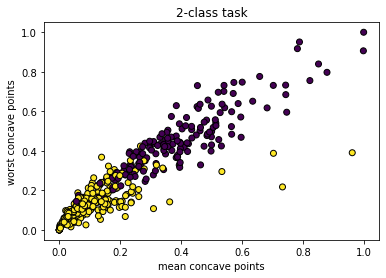

In [40]:
#根据被筛选的特征绘制的散点图
plt.scatter(X_train_new[:, 0], X_train_new[:, 1], c=y_train, cmap='viridis', marker='o', edgecolor='k') 

# 添加标题和轴标签 
plt.title("2-class task")  
plt.xlabel("mean concave points")  
plt.ylabel("worst concave points")  
plt.show()

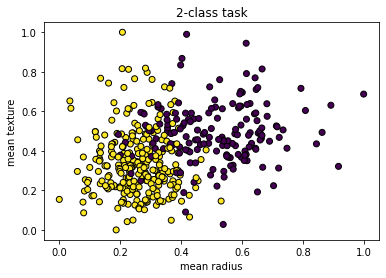

In [41]:
#尝试任意两个特征绘制的散点图
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='viridis', marker='o', edgecolor='k') 

# 添加标题和轴标签 
plt.title("2-class task")  
plt.xlabel("mean radius")  
plt.ylabel("mean texture")  
plt.show()

- 使用seaborn优化你的绘图（选修内容，不讲解，仅作为展示）

In [44]:
import seaborn as sns 

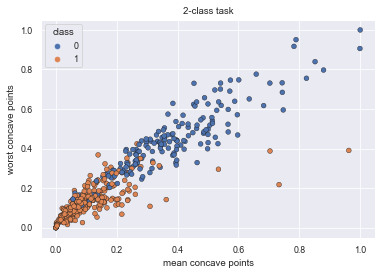

In [45]:
# 使用seaborn绘制散点图  
sns.scatterplot(data=X_train_new, x=X_train_new[:, 0], y=X_train_new[:, 1], hue=y_train,  marker='o', edgecolor='k')  #palette='viridis',
sns.set_theme()  
sns.set_context("paper")
#sns.set_context("talk")
#sns.set_context("poster")
#sns.set_context("notebook", font_scale=1.5, rc={"lines.linewidth": 2.5})

# 添加标题和轴标签 
plt.title("2-class task")  
plt.xlabel("mean concave points")  
plt.ylabel("worst concave points")  
# 显示图形  
plt.show()

## 2.3监督学习算法

### 2.3.1.监督学习算法-回归

表常见的回归模型

| 回归模型名称   | 库名称                     |
|----------------|----------------------------|
| 线性回归       | LinearRegression           |
| 岭回归         | Ridge                      |
| LASSO回归      | LASSO                      |
| ElasticNet回归 | ElasticNet                 |
| 决策树回归     | tree.DecisionTreeRegressor |

代码示例：

In [46]:
#从线性模型库导入线性回归模型
from sklearn.linear_model import LinearRegression
# 构建模型实例
lr = LinearRegression(normalize=True)
# 训练模型
lr.fit(X_train, y_train)
# 作出预测
y_pred = lr.predict(X_test)

### 2.3.2.监督学习算法-分类

表常见的分类模型

| 模型名称   | 库名称                               |
|------------|--------------------------------------|
| 逻辑回归   | linear model.LogisticRearession      |
| 支持向量机 | svm.SVC                              |
| 朴素贝叶斯 | naïve_bayes.GaussianNB               |
| KNN        | neighbors.NearestNeighbors           |
| 随机森林   | ensemble.RandomForestClassifier      |
| GBDT       | ensemble.GradientBoostingClassifier  |

代码示例：

In [47]:
from sklearn.linear_model import LogisticRegression  
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.model_selection import learning_curve  

In [48]:
# 创建逻辑回归模型  
# 默认使用的是L2正则化，即Ridge正则化  
model = LogisticRegression(max_iter=200)  # 增加max_iter以避免在大数据集上收敛问题

- 使用筛选出的2个最重要的特征训练模型

In [49]:
# 训练模型  
model.fit(X_train_new, y_train)
# 使用测试集进行预测  
y_pred = model.predict(X_test_new) 

In [50]:
# 计算并打印准确率  
accuracy = accuracy_score(y_test, y_pred)  
print(f'Accuracy: {accuracy:.2f}')

Accuracy: 0.92


In [51]:
#查看学习到的参数
model.coef_ 

array([[-3.86632, -6.51433]])

In [52]:
target_names = ['malignant', 'benign']
print(classification_report(y_test, y_pred, target_names=target_names))

              precision    recall  f1-score   support

   malignant       0.92      0.86      0.89        42
      benign       0.92      0.96      0.94        72

    accuracy                           0.92       114
   macro avg       0.92      0.91      0.91       114
weighted avg       0.92      0.92      0.92       114



- 绘制测试数据的决策边界

<ipython-input-53-12e0d10d8ad9>:18: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  plt.colorbar(label='Predicted Probability of Class 1')


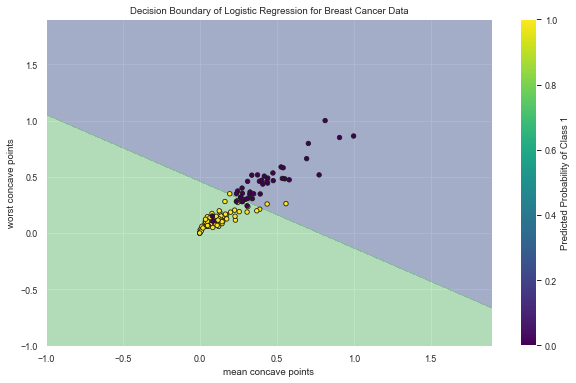

In [53]:
#生成网络数据
x_min, x_max = X_test_new[:, 0].min() - 1, X_test_new[:, 0].max() + 1  
y_min, y_max = X_test_new[:, 1].min() - 1, X_test_new[:, 1].max() + 1  
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),  
                     np.arange(y_min, y_max, 0.1))  

# 预测网格点的概率
Z = model.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1]  
Z = Z.reshape(xx.shape)  

# 绘制决策边界（这里我们使用概率的等高线图来表示决策边界）  
plt.figure(figsize=(10, 6))  
plt.contourf(xx, yy, Z, alpha=0.4, levels =1, cmap='viridis')  #试试 levels取不同值时的图表
plt.scatter(X_test_new[:, 0], X_test_new[:, 1], c=y_test, s=20, edgecolor='k', cmap='viridis')  
plt.xlabel("mean concave points")  
plt.ylabel("worst concave points")   
plt.title('Decision Boundary of Logistic Regression for Breast Cancer Data')  
plt.colorbar(label='Predicted Probability of Class 1')  
plt.show()

-  绘制训练数据的决策边界

<ipython-input-54-d887d5315a67>:18: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  plt.colorbar(label='Predicted Probability of Class 1')


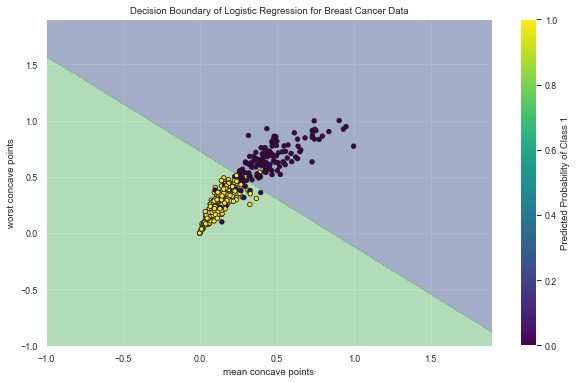

In [54]:
#生成网络数据
x_min, x_max = X_train_new[:, 0].min() - 1, X_train_new[:, 0].max() + 1  
y_min, y_max = X_train_new[:, 1].min() - 1, X_train_new[:, 1].max() + 1  
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),  
                     np.arange(y_min, y_max, 0.1))  

# 预测网格点的概率
Z = model.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1]  
Z = Z.reshape(xx.shape)  

# 绘制决策边界（这里我们使用概率的等高线图来表示决策边界）  
plt.figure(figsize=(10, 6))  
plt.contourf(xx, yy, Z, alpha=0.4, levels =1, cmap='viridis')  #试试 levels 取不同值时的图表  
plt.scatter(X_train_new[:, 0], X_train_new[:, 1], c=y_train, s=20, edgecolor='k', cmap='viridis')  
plt.xlabel("mean concave points")  
plt.ylabel("worst concave points")   
plt.title('Decision Boundary of Logistic Regression for Breast Cancer Data')  
plt.colorbar(label='Predicted Probability of Class 1')  
plt.show()

- 使用所有特征训练模型

In [54]:
# 创建逻辑回归模型  
# 默认使用的是L2正则化，即Ridge正则化  
model = LogisticRegression(max_iter=200)  # 增加max_iter以避免在大数据集上收敛问题
# 训练模型  
model.fit(X_train, y_train)
# 使用测试集进行预测  
y_pred = model.predict(X_test) 
# 计算并打印准确率  
accuracy = accuracy_score(y_test, y_pred)  
print(f'Accuracy: {accuracy:.2f}')

Accuracy: 0.97


In [55]:
#查看学习到的参数
model.coef_ 

array([[-1.76887, -1.75318, -1.70588, -1.44622, -0.71802, -0.36619,
        -1.39205, -2.00421, -0.29389,  0.7767 , -1.0947 ,  0.013  ,
        -0.90135, -0.67924,  0.03753,  0.652  ,  0.27651, -0.11552,
         0.2296 ,  0.56682, -2.14979, -2.09966, -1.9913 , -1.55962,
        -1.45854, -0.82054, -1.41614, -2.45937, -1.33808, -0.42222]])

In [56]:
target_names = ['malignant', 'benign']
print(classification_report(y_test, y_pred, target_names=target_names))

              precision    recall  f1-score   support

   malignant       1.00      0.93      0.96        42
      benign       0.96      1.00      0.98        72

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



## 2.4 交叉验证

交叉验证的方法如图，具体原理在第7章“机器学习实践”中有讲解，本章仅讲解使用方法。

![](images/2daa4a9b0a9881b23397ae6ddca0ff53.png)


代码示例：

- 重新加载数据，并使用交叉验证评估模型

In [2]:
#导入内置的乳腺癌数据集
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()
#定义数据、标签
X = cancer.data
y = cancer.target

In [3]:
from sklearn.model_selection import cross_validate,StratifiedKFold 

from sklearn.preprocessing import StandardScaler,MinMaxScaler

#构建转换器实例
scaler = MinMaxScaler()#实例化
#拟合及转换数据
X= scaler.fit_transform(X)

In [14]:
from sklearn.linear_model import LogisticRegression  
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.model_selection import learning_curve  
model = LogisticRegression(max_iter=200)

In [15]:
# 定义多个评估指标  
scoring = ['accuracy','precision_macro', 'recall_macro', 'f1_macro']  

In [16]:
skf = StratifiedKFold(n_splits=5)
# 执行交叉验证  
scores = cross_validate(model, X, y, scoring=scoring, cv=skf,  return_train_score = False) 
#scores = cross_validate(clf, X_train, y_train, cv=skf,  return_train_score = False) 

In [17]:
scores

{'fit_time': array([0.01097059, 0.01296568, 0.01196837, 0.01097035, 0.01196718]),
 'score_time': array([0.00299168, 0.00299168, 0.00299191, 0.00299191, 0.00299263]),
 'test_accuracy': array([0.95614035, 0.96491228, 0.97368421, 0.95614035, 0.96460177]),
 'test_precision_macro': array([0.96047297, 0.97333333, 0.98      , 0.96051282, 0.96695205]),
 'test_recall_macro': array([0.94644612, 0.95348837, 0.96428571, 0.94543651, 0.95724346]),
 'test_f1_macro': array([0.95263814, 0.96191113, 0.9712774 , 0.952129  , 0.96172087])}

In [18]:
# 输出结果  
print(scores.keys())  # 查看返回的字典中包含哪些键  
print(scores['test_precision_macro'])  # 输出测试集上的宏平均精确率  
print(scores['test_precision_macro'])  # 输出测试集上的宏平均精确率  
print(scores['test_recall_macro'])     # 输出测试集上的宏平均召回率  
print(scores['test_f1_macro'])         # 输出测试集上的宏平均F1值

dict_keys(['fit_time', 'score_time', 'test_accuracy', 'test_precision_macro', 'test_recall_macro', 'test_f1_macro'])
[0.96047297 0.97333333 0.98       0.96051282 0.96695205]
[0.96047297 0.97333333 0.98       0.96051282 0.96695205]
[0.94644612 0.95348837 0.96428571 0.94543651 0.95724346]
[0.95263814 0.96191113 0.9712774  0.952129   0.96172087]


- cross_val_score    https://scikit-learn.org.cn/view/663.html#
- cross_val_score 与cross_validate类似， 但 scoring 只允许使用一个评价指标

In [22]:
from sklearn.model_selection import cross_val_score       

In [23]:
model_test = LogisticRegression(max_iter=200)
cv_results = cross_val_score(model_test, X, y, cv=5, scoring = 'f1_macro' ) 
cv_results

array([0.95263814, 0.96191113, 0.9712774 , 0.952129  , 0.96172087])

In [24]:
model_test = LogisticRegression(max_iter=200)
cv_results = cross_val_score(model_test, X, y, cv=5, scoring = 'accuracy' ) 
cv_results

array([0.95614035, 0.96491228, 0.97368421, 0.95614035, 0.96460177])

## 2.5 评价指标

sklearn.metrics模块包含了一系列用于评价模型的评分函数、损失函数以及成对数据的距离度量函数。评价指标主要分为分类评价指标、回归评价指标等等，这里列举了常见的几种评价指标。

评价指标使用的方法如下：

`from sklearn.metrics import 库名称`


| 评价指标             | 库名称                | 使用范围 |
|----------------------|-----------------------|----------|
| 正确率               | accuracy_score        | 分类     |
| 精确率               | precision_score       | 分类     |
| F1 值                | f1_score              | 分类     |
| 对数损失             | log_loss              | 分类     |
| 混淆矩阵             | confusion_matrix      | 分类     |
| 含多种评价的分类报告 | classification_report | 分类     |
| 均方误差MSE          | mean_squared_error    | 回归     |
| 平均绝对误差MAE      | mean_absolute_error   | 回归     |
| 决定系数R2           | r2_score              | 回归     |

代码示例：

### 下面的代码仅仅用做讲解使用，运行可能会出错！！！

In [ ]:
#从评价指标库导入准确率
from sklearn.metrics import accuracy_score
#计算样本的准确率
accuracy_score(y_test, y_pred)
#对于测试集而言，大部分函数都必须包含真实值y_test和预测值y_pred

In [ ]:
#从模型选择库导入交叉验证分数  
from sklearn.model_selection import cross_val_score    
clf = DecisionTreeClassifier(max_depth=5)  
#使用5折交叉验证对决策树模型进行评估，使用的评分函数为F1值  
scores = cross_val_score(clf, X_train, y_train,cv=5, scoring='f1_weighted')

## 3. Scikit-learn总结

Scikit-learn是基于 Python 语言的机器学习工具，它建立在 NumPy、SciPy、Pandas和Matplotlib之上，被广泛地用于统计分析和机器学习建模等数据科学领域，其主要优点包括：

- 建模方便：用户通过Scikit-learn能够实现各种监督和非监督学习的模型，仅仅需要几行代码就可以实现。
- 功能多样：使用Scikit-learn还能够进行数据的预处理、特征工程、数据集切分、模型评估等工作。
- 数据丰富：内置丰富的数据集，比如：泰坦尼克、鸢尾花等，还可以生成数据，非常方便。

参考文献

[1] PEDREGOSA F, VAROQUAUX G, GRAMFORT A, et al. Scikit-learn: Machine Learning
in Python[J]. Journal of Machine Learning Research, 2011, 12: 2825–2830.

[2] Andrew Ng. Machine Learning[EB/OL]. StanfordUniversity,2014.https://www.coursera.org/course/ml

In [1]:
from sklearn import datasets, linear_model
from sklearn.model_selection import cross_val_score
diabetes = datasets.load_diabetes()
X = diabetes.data[:150]
y = diabetes.target[:150]
lasso = linear_model.Lasso()
print(cross_val_score(lasso, X, y, cv=5))

[0.33150734 0.08022311 0.03531764]


In [ ]:
print("Accuracy: %0.2f (+/- %0.2f)" % (scores.mean(), scores.std() * 2))